# Fish gains × signed-electrode gains (4-fish, Kaden masks, 1365-EOD clean emitter set)

**Ratios.** As in `EOD_gain_ratios_top2_fish_pair_ls_4fish_kaden.ipynb`: for each of the 1365 EODs, the 2 pairs with the
largest recorded |amplitude|, $g = |V_\text{rec}| / |V_\text{pred}|$ for the emitter (my model: main phase, unit current; Denis':
peak-to-peak, his units; both on my mask midline). Ratios with the wrong sign or |prediction| < 5% of the emitter's largest are
left out (as before).

**Signed electrode.** Each ratio is assigned to the electrode of its pair (+ or −) that is nearer to the emitter's midline
(`EOD_ratio_by_signed_electrode_4fish_kaden.ipynb`): 20 possible electrodes, some with no ratios.

**Fit.** Least squares on the ratios, 4 fish factors and one factor per signed electrode, each electrode factor the same for all
four fish:
$$\min_{a,\,e}\ \sum_i \big(g_i - a_{f(i)}\, e_{k(i)}\big)^2$$
(k(i) = the signed electrode of ratio i). Alternating least squares from 1, 300 iterations; the electrode factors are scaled to
a geometric mean of 1 over the electrodes with ratios (only the products are determined). For comparison: the earlier fit with
one factor per pair.

**Length.** Fish factor $a_f$ against fish length L (A 15.65, B 13.10, C 9.82, D 8.51 cm): linear $a = sL + c$ and power law
$a = kL^e$ (least squares on log a vs log L), through the 4 fish factors. 95% intervals: 2000 bootstrap resamples of EODs
(both ratios of an EOD together), refitting all factors each time.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import TwoSlopeNorm
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set'
OUT = f'{SRC}/gain_fish_x_signed_electrode'; os.makedirs(OUT, exist_ok=True)
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
POLE_COL = {'+': '#33332F', '−': '#B5B5AF'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}; LF = np.array([L_CM[f] for f in LET])
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]
MODELS, NBOOT = ('mine', 'Denis'), 2000
UNIT = {'mine': 'V per model unit', 'Denis': 'V per Denis unit'}; WHO = {'mine': 'my', 'Denis': "Denis'"}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv')
XY = {}
for _, e in EL.iterrows():
    for x, y, s in ((e.x1, e.y1, str(e.pol1).strip()), (e.x2, e.y2, str(e.pol2).strip())):
        XY[f'{int(e.pair)}{"+" if s == "+" else "−"}'] = (x, y)
DATA = {m: pd.read_csv(f'{SRC}/ratio_by_signed_electrode/ratios_{m}_1365_by_signed_electrode.csv') for m in MODELS}
PAIRFIT = pd.read_csv(f'{SRC}/gain_ratios_top2/fish_and_pair_factors.csv')
PAIRFIT = PAIRFIT[PAIRFIT.set == '1365 passing']

def fit_ls(g, fi, ki, nk, iters=300):
    '''min sum (g - a[fi] e[ki])^2, alternating least squares; e scaled to geometric mean 1 over electrodes with ratios.'''
    a, e = np.ones(4), np.ones(nk)
    nf = np.bincount(fi, minlength=4) > 0; ne = np.bincount(ki, minlength=nk) > 0
    for _ in range(iters):
        ee = e[ki]; a = np.where(nf, np.bincount(fi, g * ee, 4) / np.maximum(np.bincount(fi, ee * ee, 4), 1e-300), np.nan)
        aa = a[fi]; e = np.where(ne, np.bincount(ki, g * aa, nk) / np.maximum(np.bincount(ki, aa * aa, nk), 1e-300), np.nan)
    c = np.exp(np.nanmean(np.log(e))); return a * c, e / c

def arrays(d, key):
    levels = ORDER if key == 'electrode' else list(range(1, 11))
    return d.gain.to_numpy(), d.fish.map(LET.index).to_numpy(), d[key].map({v: i for i, v in enumerate(levels)}).to_numpy(), len(levels)

def r2(y, yh): return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()

FIT, rows = {}, []
for m in MODELS:
    d = DATA[m]; g, fi, ki, nk = arrays(d, 'electrode'); a, e = fit_ls(g, fi, ki, nk); FIT[m] = (a, e)
    gp, fp, pp, npair = arrays(d, 'pair'); ap, bp = fit_ls(gp, fp, pp, npair)
    print(f'{m}: {len(d)} ratios; R² of the ratios: fish × pair {r2(gp, ap[fp] * bp[pp]) * 100:.1f}%, '
          f'fish × signed electrode {r2(g, a[fi] * e[ki]) * 100:.1f}%; median |g − ĝ| / g: fish × pair '
          f'{np.median(np.abs(gp - ap[fp] * bp[pp]) / gp):.3f}, fish × signed electrode {np.median(np.abs(g - a[fi] * e[ki]) / g):.3f}')
    for j, f in enumerate(LET):
        rows.append(dict(model=m, factor=f'fish {f}', value=a[j], n=int((fi == j).sum()), pair_fit=ap[j]))
    for k, el in enumerate(ORDER):
        rows.append(dict(model=m, factor=f'electrode {el}', value=e[k], n=int((ki == k).sum()), pair_fit=np.nan))
F = pd.DataFrame(rows); F.to_csv(f'{OUT}/fish_and_signed_electrode_factors.csv', index=False)
show = F.pivot_table(index='factor', columns='model', values=['value', 'pair_fit', 'n'], sort=False)
show.columns = [f'{m}: {"fish × electrode fit" if v == "value" else ("fish × pair fit" if v == "pair_fit" else "n ratios")}' for v, m in show.columns]
display(show[[c for m in MODELS for c in show.columns if c.startswith(m)]].round(4))

mine: 2730 ratios; R² of the ratios: fish × pair 40.3%, fish × signed electrode 44.0%; median |g − ĝ| / g: fish × pair 0.169, fish × signed electrode 0.165
Denis: 2725 ratios; R² of the ratios: fish × pair 52.6%, fish × signed electrode 63.2%; median |g − ĝ| / g: fish × pair 0.210, fish × signed electrode 0.121


,mine: fish × electrode fit,mine: n ratios,mine: fish × pair fit,Denis: fish × electrode fit,Denis: n ratios,Denis: fish × pair fit
factor,,,,,,
fish A,0.5058,752.0,0.5242,0.0067,752.0,0.0071
fish B,0.3920,1450.0,0.3585,0.0045,1448.0,0.0038
fish C,0.4976,296.0,0.4985,0.0061,295.0,0.0062
fish D,0.3620,232.0,0.3699,0.0043,230.0,0.0045
electrode 1+,1.2874,1.0,NaN,0.9906,1.0,NaN
electrode 1−,0.9675,103.0,NaN,0.8795,103.0,NaN
electrode 2+,0.7226,559.0,NaN,0.7933,557.0,NaN
electrode 2−,0.9281,1.0,NaN,1.0880,1.0,NaN
electrode 3+,1.0211,35.0,NaN,0.9842,35.0,NaN


## Fish factor vs fish length

model,mine,Denis
parameter,,
fish A,"0.5058 [0.4885, 0.5261]","0.006745 [0.006578, 0.006925]"
fish B,"0.392 [0.3775, 0.4095]","0.004495 [0.004385, 0.00463]"
fish C,"0.4976 [0.464, 0.5385]","0.006085 [0.005811, 0.006504]"
fish D,"0.362 [0.3286, 0.3974]","0.004261 [0.00404, 0.004465]"
slope s (per cm),"0.01066 [0.005882, 0.0153]","0.0002045 [0.0001668, 0.0002411]"
intercept c,"0.3139 [0.253, 0.3779]","0.00299 [0.002518, 0.003506]"
exponent e,"0.2943 [0.158, 0.4359]","0.4251 [0.3513, 0.5036]"
k,"0.2122 [0.1479, 0.3039]","0.001879 [0.001535, 0.002282]"


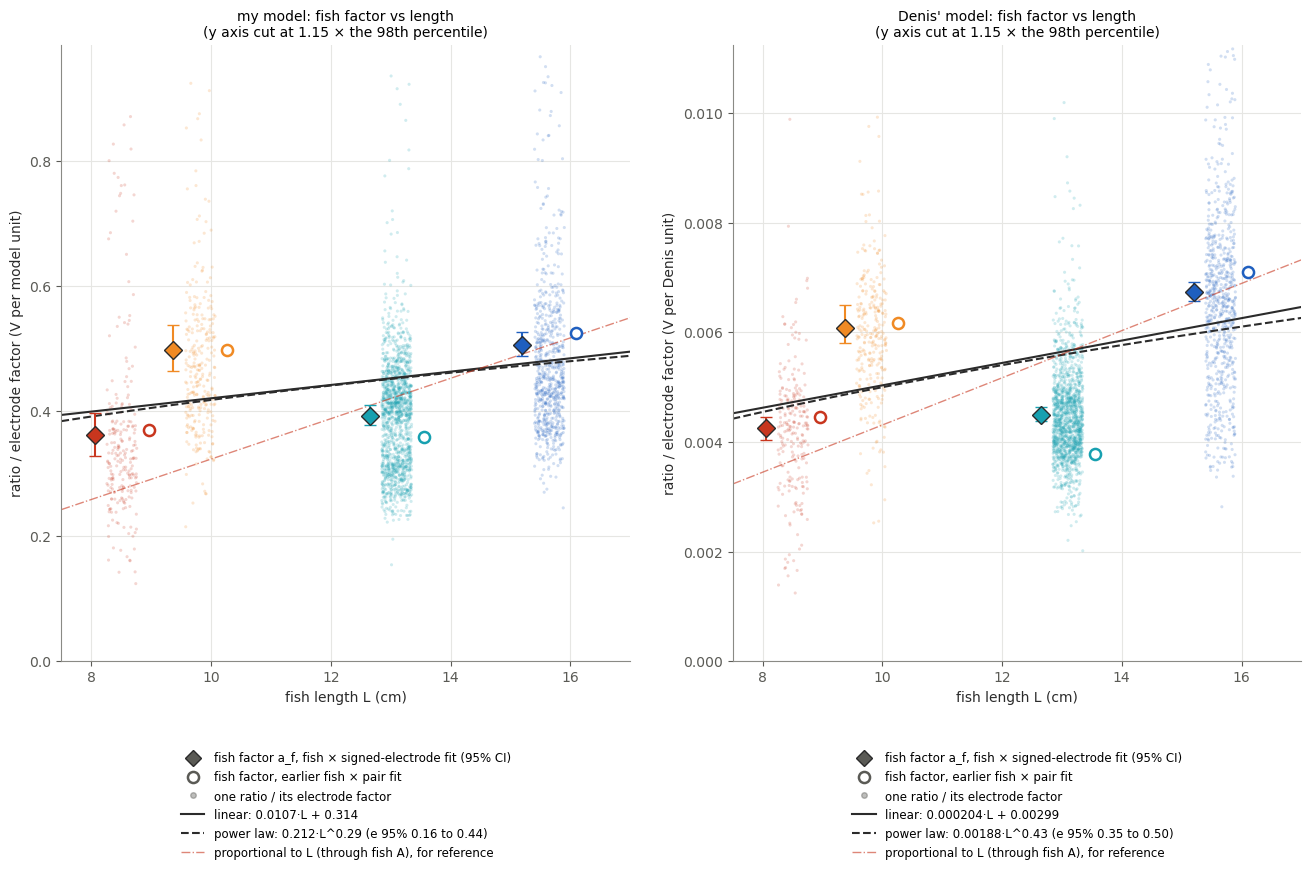

In [2]:
def length_fits(x, y):
    ok = np.isfinite(y) & (y > 0)
    s, c = np.polyfit(x[ok], y[ok], 1); e_, lk = np.polyfit(np.log(x[ok]), np.log(y[ok]), 1)
    return np.array([s, c, e_, np.exp(lk)])

rng = np.random.default_rng(0); BOOT, BOOT_E, LFIT, rows = {}, {}, {}, []
NAMES = ['slope s (per cm)', 'intercept c', 'exponent e', 'k']
for m in MODELS:
    d = DATA[m]; a, _ = FIT[m]; LFIT[m] = length_fits(LF, a)
    grp = list(d.groupby('eod').indices.values()); B = []
    for _ in range(NBOOT):
        db = d.iloc[np.concatenate([grp[i] for i in rng.integers(0, len(grp), len(grp))])]
        g, fi, ki, nk = arrays(db, 'electrode'); ab, eb = fit_ls(g, fi, ki, nk, iters=150)
        B.append(np.r_[ab, length_fits(LF, ab) if np.isfinite(ab).sum() >= 3 else [np.nan] * 4, eb])
    B = np.array(B); BOOT_E[m] = B[:, 8:]; B = B[:, :8]; BOOT[m] = B; lo, hi = np.nanpercentile(B, [2.5, 97.5], axis=0)
    for k, nm in enumerate([f'fish {f}' for f in LET] + NAMES):
        est = a[k] if k < 4 else LFIT[m][k - 4]
        rows.append(dict(model=m, parameter=nm, estimate=est, ci_low=lo[k], ci_high=hi[k]))
FT = pd.DataFrame(rows); FT.to_csv(f'{OUT}/fish_factors_and_length_fits.csv', index=False)
display(FT.assign(value=[f'{e:.4g}  [{l:.4g}, {h:.4g}]' for e, l, h in zip(FT.estimate, FT.ci_low, FT.ci_high)])
          .pivot_table(index='parameter', columns='model', values='value', aggfunc='first', sort=False)[list(MODELS)])

fig, axs = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw=dict(wspace=0.18))
xs = np.linspace(7.5, 17, 100); jit = np.random.default_rng(1)
for ax, m in zip(axs, MODELS):
    d = DATA[m]; a, e = FIT[m]; g, fi, ki, nk = arrays(d, 'electrode'); y = g / e[ki]
    lo, hi = np.nanpercentile(BOOT[m][:, :4], [2.5, 97.5], axis=0); s, c, ex, k = LFIT[m]
    ci = FT[(FT.model == m) & (FT.parameter == 'exponent e')].iloc[0]
    pf = PAIRFIT[PAIRFIT.model == m].set_index('factor').LS
    for j, f in enumerate(LET):
        kk = fi == j
        ax.scatter(LF[j] + jit.uniform(-0.25, 0.25, kk.sum()), y[kk], s=5, alpha=0.2, color=FISH_COL[f], edgecolor='none', zorder=2)
        ax.errorbar(LF[j] - 0.45, a[j], yerr=[[a[j] - lo[j]], [hi[j] - a[j]]], fmt='D', ms=9, color=FISH_COL[f], mec='#2b2b2b', capsize=4, zorder=4)
        ax.plot(LF[j] + 0.45, pf[f'fish {f}'], 'o', ms=8, mfc='white', mec=FISH_COL[f], mew=1.8, zorder=4)
    ax.plot(xs, s * xs + c, color='#2b2b2b', lw=1.5, label=f'linear: {s:.3g}·L {"+" if c >= 0 else "−"} {abs(c):.3g}')
    ax.plot(xs, k * xs ** ex, color='#2b2b2b', lw=1.5, ls='--', label=f'power law: {k:.3g}·L^{ex:.2f} (e 95% {ci.ci_low:.2f} to {ci.ci_high:.2f})')
    ax.plot(xs, a[0] * xs / LF[0], color='#C8361E', lw=1, ls='-.', alpha=0.6, label='proportional to L (through fish A), for reference')
    ax.set(xlim=(7.5, 17), ylim=(0, np.percentile(y, 98) * 1.15), xlabel='fish length L (cm)', ylabel=f'ratio / electrode factor ({UNIT[m]})')
    ax.set_title(f'{WHO[m]} model: fish factor vs length\n(y axis cut at 1.15 × the 98th percentile)', fontsize=10)
    h = [Line2D([], [], marker='D', ls='', ms=8, color='#5a5a55', mec='#2b2b2b', label='fish factor a_f, fish × signed-electrode fit (95% CI)'),
         Line2D([], [], marker='o', ls='', ms=8, mfc='white', mec='#5a5a55', mew=1.8, label='fish factor, earlier fish × pair fit'),
         Line2D([], [], marker='o', ls='', ms=4, color='#5a5a55', alpha=0.4, label='one ratio / its electrode factor')]
    ax.legend(handles=h + ax.get_legend_handles_labels()[0], frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13))
fig.savefig(f'{OUT}/fish_factor_vs_length.png', dpi=110, bbox_inches='tight'); plt.show()

## Fish factor vs length, per video

The signed-electrode factors are kept at the all-video fit above; in each video only the 4 fish factors are refitted by least
squares on that video's ratios, $a_f = \sum g\, e_k / \sum e_k^2$ over fish f's ratios in the video (so the fish factors of
different videos are on the same scale). A fish factor is drawn only with ≥ 10 ratios of that fish in the video. Length fits
(linear and power law) through the fish factors of the video when it has ≥ 2 such fish; with 2 or 3 fish they are close to
exact and the bootstrap interval (2000 resamples of that video's EODs) is the only measure of how well they are pinned.
Open circles: the all-video fish factors, for reference.

/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


my model: fish factors (electrode factors fixed at the all-video fit) and length fits, per video


/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/lencacuturela/opt/anaconda3/envs/electric_fish/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


video,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25
parameter,,,,,
fish A,"0.5184 [0.4834, 0.56]","0.5144 [0.4883, 0.5441]",–,"0.4274 [0.4031, 0.4547]",–
fish B,"0.3446 [0.2823, 0.4361]","0.3064 [0.2943, 0.3183]",–,"0.4156 [0.4066, 0.4255]","0.3672 [0.3475, 0.3882]"
fish C,"0.5033 [0.4572, 0.5612]","0.454 [0.4138, 0.4929]",–,"0.5369 [0.5024, 0.5744]",–
fish D,"0.4148 [0.3666, 0.4679]","0.2995 [0.2853, 0.3135]",–,–,"0.3391 [0.3048, 0.3796]"
slope s (per cm),"0.004353 [-0.004644, 0.01278]","0.01734 [0.01294, 0.02217]",–,"-0.01965 [-0.02711, -0.01223]","0.006132 [-0.003629, 0.0148]"
intercept c,"0.394 [0.2957, 0.5016]","0.1895 [0.1331, 0.2439]",–,"0.7125 [0.6131, 0.8167]","0.2869 [0.1821, 0.4095]"
exponent e,"0.06687 [-0.1891, 0.3072]","0.4794 [0.3635, 0.5992]",–,"-0.528 [-0.711, -0.3377]","0.1849 [-0.1034, 0.4599]"
k,"0.3734 [0.2086, 0.6825]","0.119 [0.08824, 0.1594]",–,"1.743 [1.073, 2.796]","0.2282 [0.1141, 0.4756]"


Denis' model: fish factors (electrode factors fixed at the all-video fit) and length fits, per video


video,05_52_55,06_52_55,11_12_57,15_16_23,19_16_25
parameter,,,,,
fish A,"0.007066 [0.006784, 0.007393]","0.006651 [0.006436, 0.006898]",–,"0.006016 [0.005609, 0.006437]",–
fish B,"0.004066 [0.003735, 0.004418]","0.004252 [0.004143, 0.004353]",–,"0.004564 [0.004504, 0.004624]","0.004449 [0.004283, 0.004644]"
fish C,"0.006084 [0.005653, 0.006628]","0.006202 [0.005606, 0.006879]",–,"0.005976 [0.005731, 0.006234]",–
fish D,"0.004438 [0.004131, 0.004723]","0.004056 [0.003777, 0.004314]",–,–,"0.004264 [0.003914, 0.004613]"
slope s (per cm),"0.0002076 [0.0001501, 0.0002691]","0.0001966 [0.0001398, 0.0002535]",–,"-1.347e-05 [-9.626e-05, 6.662e-05]","4.044e-05 [-4.249e-05, 0.0001237]"
intercept c,"0.002969 [0.002203, 0.003734]","0.002976 [0.002176, 0.003779]",–,"0.005692 [0.004698, 0.006667]","0.00392 [0.002886, 0.004957]"
exponent e,"0.3765 [0.2505, 0.5133]","0.4241 [0.3057, 0.5526]",–,"-0.07648 [-0.2473, 0.08466]","0.09878 [-0.1007, 0.3121]"
k,"0.002108 [0.001501, 0.002868]","0.001837 [0.001313, 0.002501]",–,"0.006646 [0.004421, 0.01009]","0.003451 [0.002019, 0.00569]"


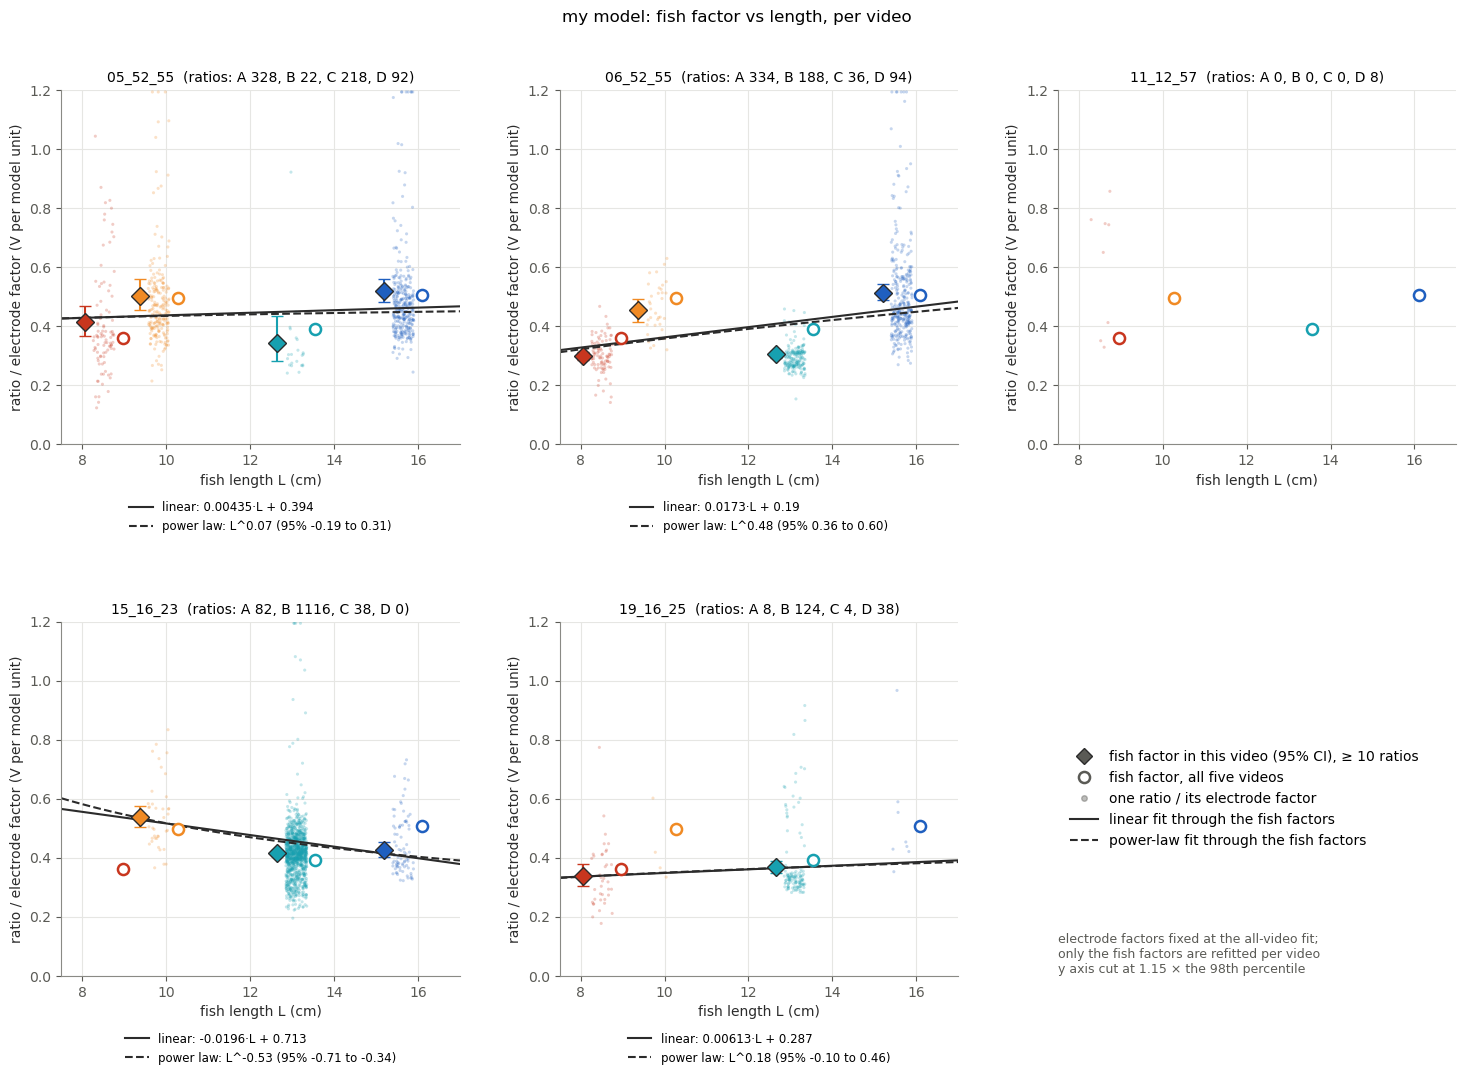

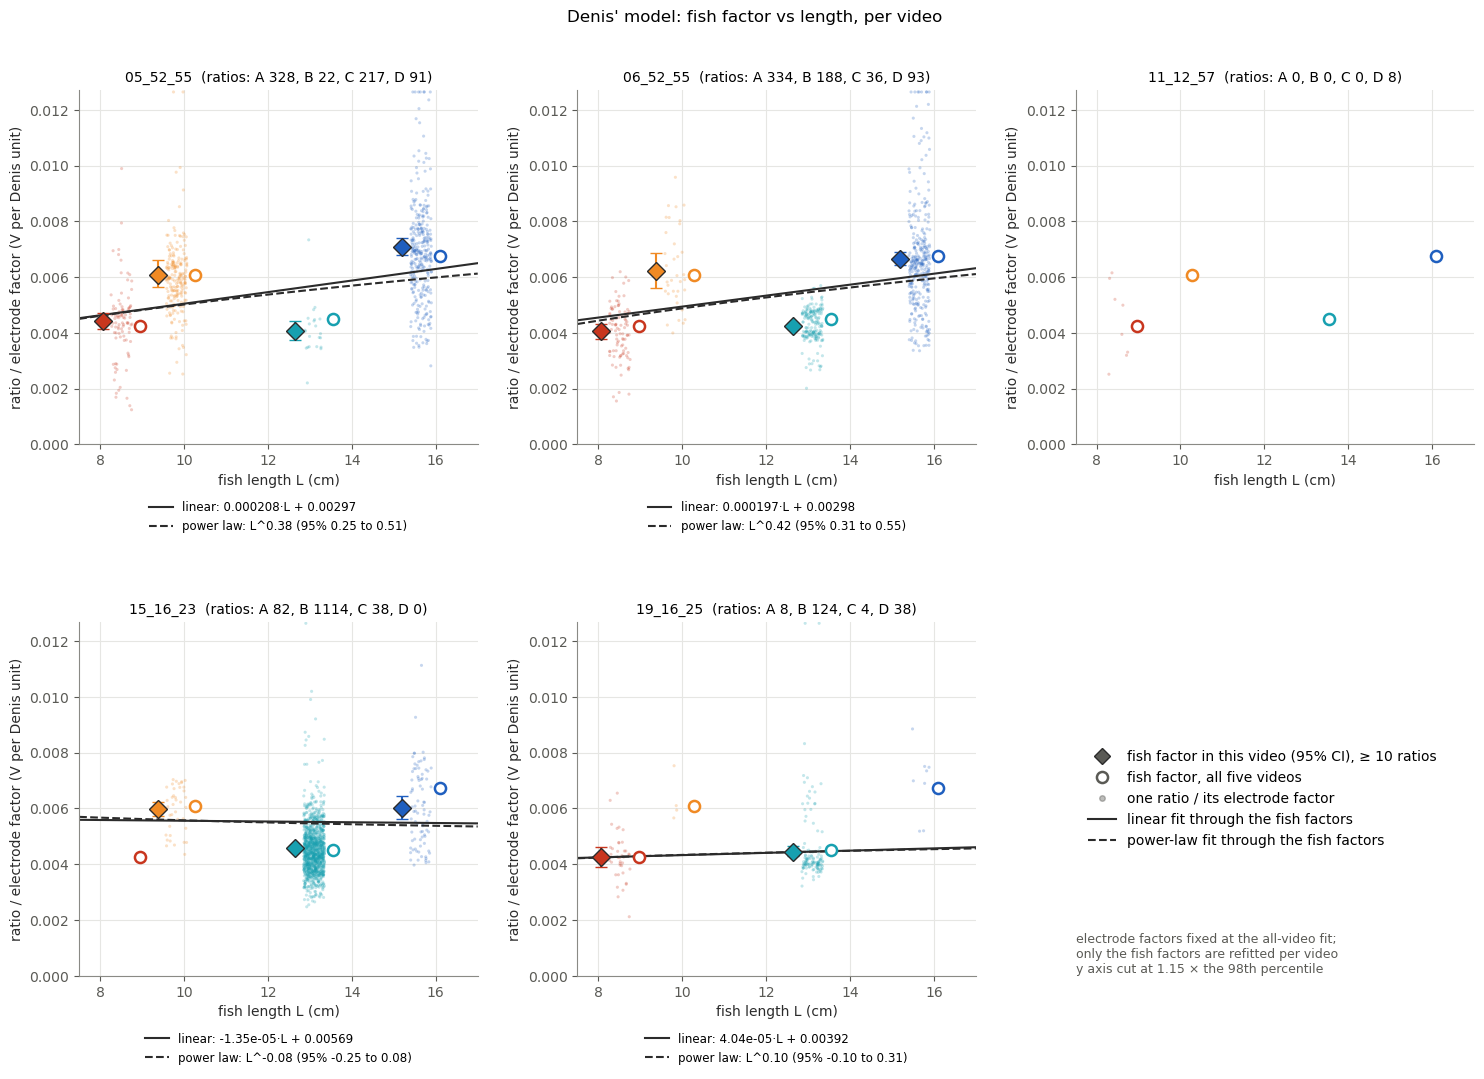

In [3]:
VIDS = sorted(DATA['mine'].video.unique()); MIN_N = 10
rng = np.random.default_rng(0); rows = []; PV = {}
for m in MODELS:
    d = DATA[m]; _, e = FIT[m]
    for t in VIDS:
        dv = d[d.video == t]; g, fi, ki, nk = arrays(dv, 'electrode'); ee = e[ki]
        n = np.bincount(fi, minlength=4)
        def fish_fit(g, fi, ee):
            num, den = np.bincount(fi, g * ee, 4), np.bincount(fi, ee * ee, 4)
            return np.where(den > 0, num / np.maximum(den, 1e-300), np.nan)
        a = np.where(n >= MIN_N, fish_fit(g, fi, ee), np.nan); ok = np.isfinite(a)
        est = length_fits(LF[ok], a[ok]) if ok.sum() >= 2 else np.full(4, np.nan)
        grp = list(dv.groupby('eod').indices.values()); B = []
        for _ in range(NBOOT):
            bi = np.concatenate([grp[i] for i in rng.integers(0, len(grp), len(grp))])
            ab = np.where(n >= MIN_N, fish_fit(g[bi], fi[bi], ee[bi]), np.nan)
            B.append(np.r_[ab, length_fits(LF[ok], ab[ok]) if ok.sum() >= 2 and np.isfinite(ab[ok]).all() else [np.nan] * 4])
        B = np.array(B); lo, hi = np.nanpercentile(B, [2.5, 97.5], axis=0)
        PV[(m, t)] = dict(a=a, lo=lo[:4], hi=hi[:4], est=est, elo=lo[4:], ehi=hi[4:], n=n, y=g / ee, fi=fi)
        for j, f in enumerate(LET):
            rows.append(dict(model=m, video=t, parameter=f'fish {f}', estimate=a[j], ci_low=lo[j], ci_high=hi[j], n=int(n[j])))
        for k, nm in enumerate(NAMES):
            rows.append(dict(model=m, video=t, parameter=nm, estimate=est[k], ci_low=lo[4 + k], ci_high=hi[4 + k], n=int(ok.sum())))
PVT = pd.DataFrame(rows); PVT.to_csv(f'{OUT}/fish_factors_and_length_fits_per_video.csv', index=False)
for m in MODELS:
    t_ = PVT[PVT.model == m].assign(value=lambda x: [f'{e:.4g} [{l:.4g}, {h:.4g}]' if np.isfinite(e) else '–'
                                                      for e, l, h in zip(x.estimate, x.ci_low, x.ci_high)])
    print(f'{WHO[m]} model: fish factors (electrode factors fixed at the all-video fit) and length fits, per video')
    display(t_.pivot_table(index='parameter', columns='video', values='value', aggfunc='first', sort=False))

xs = np.linspace(7.5, 17, 100)
for m in MODELS:
    a_all = FIT[m][0]; top = max(np.nanpercentile(PV[(m, t)]['y'], 98) for t in VIDS if len(PV[(m, t)]['y'])) * 1.15
    fig, axs = plt.subplots(2, 3, figsize=(18, 11.5), gridspec_kw=dict(hspace=0.5, wspace=0.25))
    jit = np.random.default_rng(1)
    for ax, t in zip(axs.ravel(), VIDS):
        r = PV[(m, t)]; a, y, fi = r['a'], r['y'], r['fi']
        for j, f in enumerate(LET):
            k = fi == j
            if k.any():
                ax.scatter(LF[j] + jit.uniform(-0.25, 0.25, k.sum()), np.minimum(y[k], top * 0.995), s=5, alpha=0.25, color=FISH_COL[f], edgecolor='none', zorder=2)
            if np.isfinite(a[j]):
                ax.errorbar(LF[j] - 0.45, a[j], yerr=[[a[j] - r['lo'][j]], [r['hi'][j] - a[j]]], fmt='D', ms=9, color=FISH_COL[f], mec='#2b2b2b', capsize=4, zorder=4)
            ax.plot(LF[j] + 0.45, a_all[j], 'o', ms=8, mfc='white', mec=FISH_COL[f], mew=1.8, zorder=4)
        s, c, ex, k_ = r['est']
        if np.isfinite(ex):
            ax.plot(xs, s * xs + c, color='#2b2b2b', lw=1.5, label=f'linear: {s:.3g}·L {"+" if c >= 0 else "−"} {abs(c):.3g}')
            ax.plot(xs, k_ * xs ** ex, color='#2b2b2b', lw=1.5, ls='--', label=f'power law: L^{ex:.2f} (95% {r["elo"][2]:.2f} to {r["ehi"][2]:.2f})')
            ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13))
        nf = ', '.join(f'{f} {int(r["n"][j])}' for j, f in enumerate(LET))
        ax.set(xlim=(7.5, 17), ylim=(0, top), xlabel='fish length L (cm)', ylabel=f'ratio / electrode factor ({UNIT[m]})')
        ax.set_title(f'{t}  (ratios: {nf})', fontsize=10)
    ax = axs.ravel()[-1]; ax.axis('off')
    h = [Line2D([], [], marker='D', ls='', ms=8, color='#5a5a55', mec='#2b2b2b', label='fish factor in this video (95% CI), ≥ 10 ratios'),
         Line2D([], [], marker='o', ls='', ms=8, mfc='white', mec='#5a5a55', mew=1.8, label='fish factor, all five videos'),
         Line2D([], [], marker='o', ls='', ms=4, color='#5a5a55', alpha=0.4, label='one ratio / its electrode factor'),
         Line2D([], [], color='#2b2b2b', lw=1.5, label='linear fit through the fish factors'),
         Line2D([], [], color='#2b2b2b', lw=1.5, ls='--', label='power-law fit through the fish factors')]
    ax.legend(handles=h, frameon=False, fontsize=10, loc='center left')
    ax.text(0, 0.12, 'electrode factors fixed at the all-video fit;\nonly the fish factors are refitted per video\n'
            'y axis cut at 1.15 × the 98th percentile', transform=ax.transAxes, fontsize=9, color='#5a5a55', va='top')
    fig.suptitle(f'{WHO[m]} model: fish factor vs length, per video', fontsize=12, y=0.95)
    fig.savefig(f'{OUT}/fish_factor_vs_length_per_video_{m}.png', dpi=110, bbox_inches='tight'); plt.show()

## Signed-electrode gains

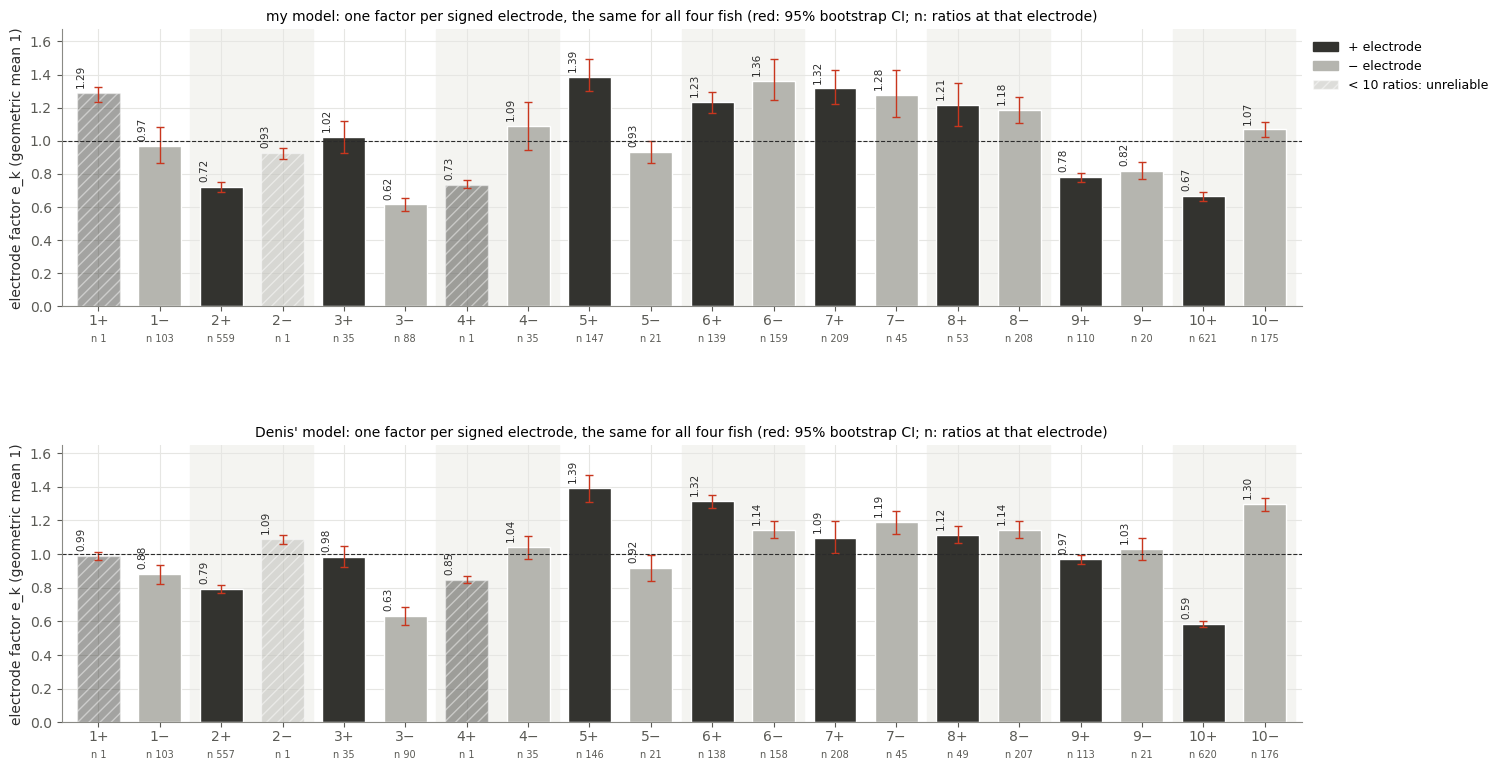

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), gridspec_kw=dict(hspace=0.5))
for ax, m in zip(axs, MODELS):
    _, e = FIT[m]; lo, hi = np.nanpercentile(BOOT_E[m], [2.5, 97.5], axis=0)
    n = F[(F.model == m) & F.factor.str.startswith('electrode')].n.to_numpy()
    x = np.arange(20)
    bars = ax.bar(x, np.nan_to_num(e), 0.7, color=[POLE_COL[el[-1]] for el in ORDER], edgecolor='white')
    for b_, nn in zip(bars, n):
        if nn < 10: b_.set_hatch('///'); b_.set_alpha(0.45)
    ok = np.isfinite(e); ax.errorbar(x[ok], e[ok], yerr=[e[ok] - lo[ok], hi[ok] - e[ok]], fmt='none', color='#C8361E', capsize=3, lw=1)
    for xi, v, nn in zip(x, e, n):
        ax.text(xi - 0.36, (v if np.isfinite(v) else 0) + 0.03, f'{v:.2f}' if np.isfinite(v) else 'no data', ha='left' if np.isfinite(v) else 'center', va='bottom', fontsize=7.5, rotation=90 if np.isfinite(v) else 0,
                color='#2b2b2b' if np.isfinite(v) else '#8a8a85')
        ax.text(xi, -0.1, f'n {nn}', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=7, color='#5a5a55')
    for p in range(10):
        if p % 2: ax.axvspan(2 * p - 0.5, 2 * p + 1.5, color='#f4f4f1', zorder=0)
    ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
    ax.set(xticks=x, xlim=(-0.6, 19.6), ylim=(0, np.nanmax(hi) * 1.12), ylabel='electrode factor e_k (geometric mean 1)')
    ax.set_xticklabels(ORDER); ax.tick_params(axis='x', pad=2)
    ax.set_title(f'{WHO[m]} model: one factor per signed electrode, the same for all four fish (red: 95% bootstrap CI; n: ratios at that electrode)', fontsize=10)
axs[0].legend(handles=[Patch(color=POLE_COL['+'], label='+ electrode'), Patch(color=POLE_COL['−'], label='− electrode'),
                       Patch(facecolor='#B5B5AF', alpha=0.45, hatch='///', edgecolor='white', label='< 10 ratios: unreliable')],
              frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(f'{OUT}/signed_electrode_factors.png', dpi=110, bbox_inches='tight'); plt.show()

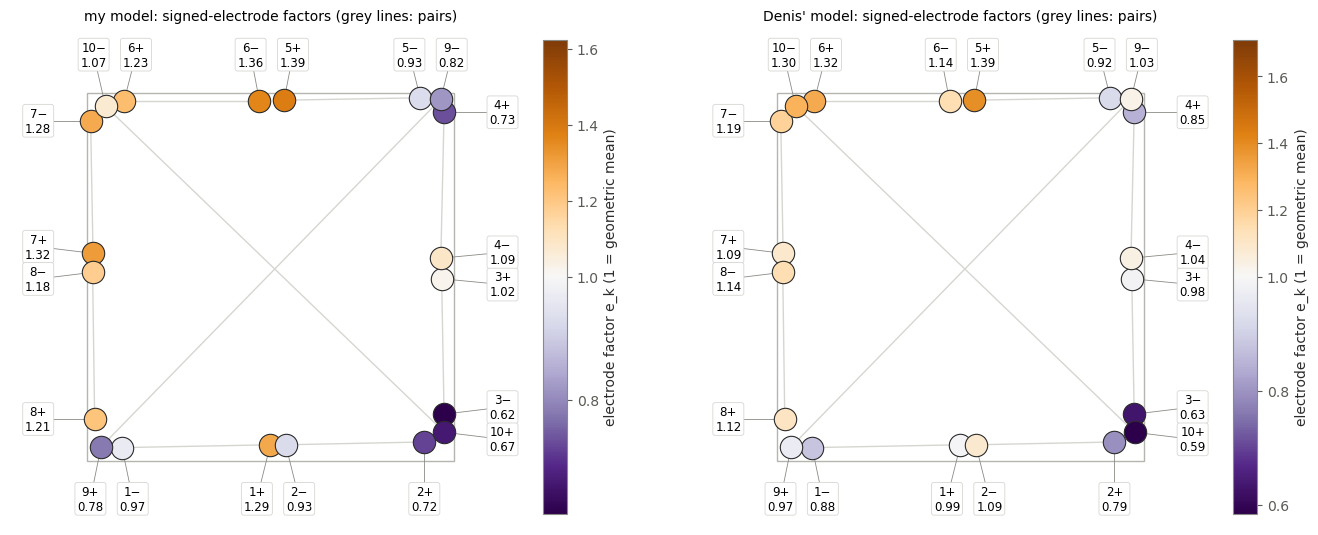

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(17, 8.2), gridspec_kw=dict(wspace=0.1))
cmap = plt.get_cmap('PuOr_r')
for ax, m in zip(axs, MODELS):
    _, e = FIT[m]; ev = dict(zip(ORDER, e))
    fin = e[np.isfinite(e)]; span = max(abs(np.log2(fin.min())), abs(np.log2(fin.max())), 0.3)
    norm = TwoSlopeNorm(vmin=2 ** -span, vcenter=1, vmax=2 ** span)
    ax.add_patch(plt.Rectangle((0, 0), P, P, fill=False, ec='#b5b5b0', lw=1))
    for _, r in EL.iterrows():
        ax.plot([r.x1, r.x2], [r.y1, r.y2], color='#d6d6d1', lw=1, zorder=1)
    LAB = {}
    for el, (x, y) in XY.items():
        v = ev[el]
        if np.isfinite(v):
            ax.scatter(x, y, s=260, color=cmap(norm(v)), edgecolor='#2b2b2b', lw=0.8, zorder=3)
            lab = f'{el}\n{v:.2f}'
        else:
            ax.scatter(x, y, s=260, facecolor='white', edgecolor='#b5b5b0', lw=1, zorder=3, hatch='///')
            lab = f'{el}\nno data'
        LAB[el] = lab
    # labels outside the nearest wall, pushed apart along that wall, joined to their electrode by a thin line
    wall = {el: min((('top', y), ('bottom', P - y), ('left', x), ('right', P - x)), key=lambda t: t[1])[0] for el, (x, y) in XY.items()}
    for w, gap, off in (('top', 105, -95), ('bottom', 105, P + 95), ('left', 80, -120), ('right', 80, P + 120)):
        els = sorted([el for el in XY if wall[el] == w], key=lambda el: XY[el][0] if w in ('top', 'bottom') else XY[el][1])
        pos = [XY[el][0] if w in ('top', 'bottom') else XY[el][1] for el in els]
        for _ in range(50):                                            # push apart, keep within the wall
            for i in range(1, len(pos)):
                if pos[i] - pos[i - 1] < gap: mid = (pos[i] + pos[i - 1]) / 2; pos[i - 1], pos[i] = mid - gap / 2, mid + gap / 2
        for el, q in zip(els, pos):
            lx, ly = (q, off) if w in ('top', 'bottom') else (off, q)
            ax.plot([XY[el][0], lx], [XY[el][1], ly], color='#8a8a85', lw=0.6, zorder=2)
            ax.text(lx, ly, LAB[el], ha='center', va='center', fontsize=8.5, zorder=4, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#d6d6d1', lw=0.6))
    ax.set(xlim=(-190, P + 190), ylim=(P + 160, -160), aspect='equal', xticks=[], yticks=[])
    ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(f'{WHO[m]} model: signed-electrode factors (grey lines: pairs)', fontsize=10)
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    fig.colorbar(sm, ax=ax, shrink=0.75, pad=0.02, label='electrode factor e_k (1 = geometric mean)')
fig.savefig(f'{OUT}/signed_electrode_factors_tank_map.png', dpi=110, bbox_inches='tight'); plt.show()

## How much of the variability of the ratios do fish and electrode factors explain?

$R^2 = 1 - \sum (g - \hat g)^2 / \sum (g - \bar g)^2$ over all 2730 (mine) / 2725 (Denis) ratios, each prediction fitted by least
squares on what it is scored on:
- **fish only**: one gain per fish (4); **electrode only**: one gain per signed electrode (20);
- **fish × electrode**: $a_f\, e_k$, the fit above.

On log ratios the same model is a sum ($\log a_f + \log e_k$), fitted by ordinary least squares.

Split of the variance (right): **shared** = fish only + electrode only − fish × electrode (fish and electrodes are confounded:
each fish sits mostly at its own electrodes); **fish unique** = fish × electrode − electrode only; **electrode unique** =
fish × electrode − fish only; **unexplained** = 1 − fish × electrode (EOD to EOD).

fish only  electrode only  fish × electrode  shared  \
model scale                                                             
mine  ratios           30.3            40.1              44.0    26.4   
      log ratios       44.1            58.8              63.6    39.4   
Denis ratios           47.3            54.4              63.2    38.5   
      log ratios       53.9            67.7              76.4    45.2   

                  fish unique  electrode unique  unexplained  
model scale                                                   
mine  ratios              3.9              13.7         56.0  
      log ratios          4.8              19.4         36.4  
Denis ratios              8.8              15.9         36.8  
      log ratios          8.7              22.5         23.6

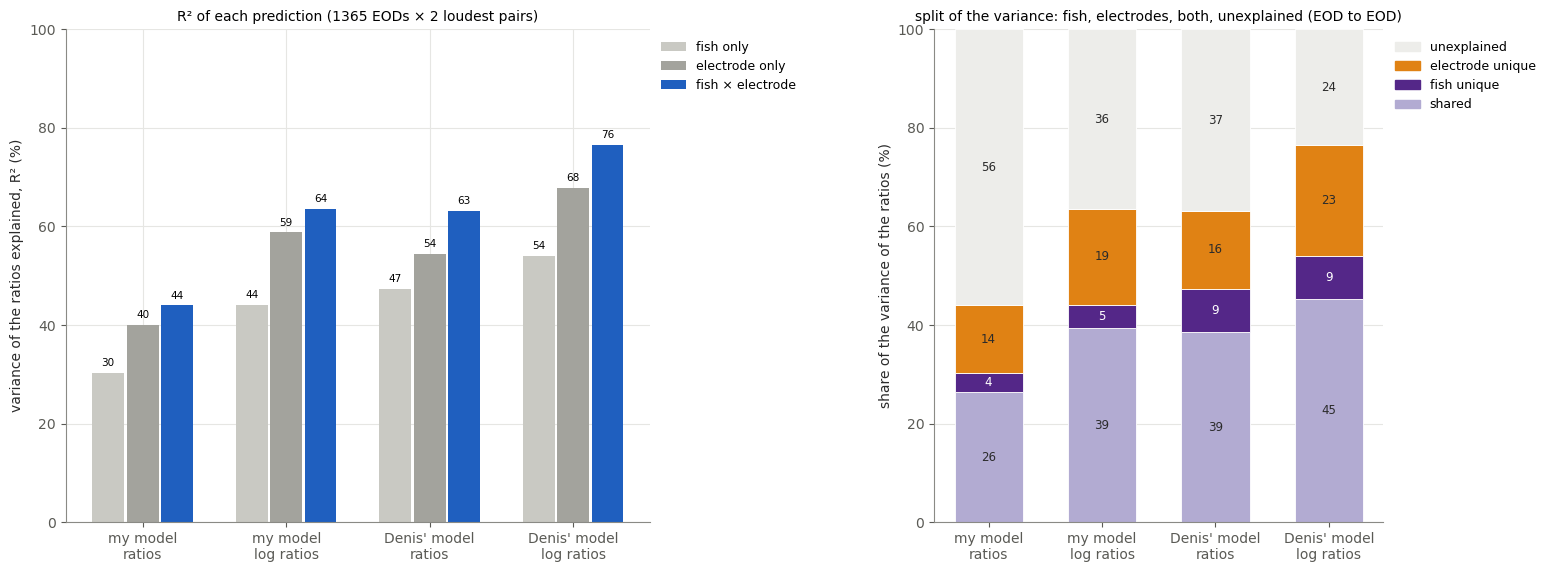

In [6]:
def fit_log(y, *codes):
    # ordinary least squares of y on dummy variables of each code (sum of factors in log)
    X = np.hstack([np.eye(c.max() + 1)[c][:, np.unique(c)] for c in codes])
    return X @ np.linalg.lstsq(X, y, rcond=None)[0]
def group_mean(y, *keys): return pd.Series(y).groupby(pd.Series(list(zip(*keys)))).transform('mean').to_numpy()

rows = []
for m in MODELS:
    g, fi, ki, nk = arrays(DATA[m], 'electrode')
    for sc in ('ratios', 'log ratios'):
        y = np.log(g) if sc == 'log ratios' else g
        y2 = FIT[m][0][fi] * FIT[m][1][ki] if sc == 'ratios' else fit_log(y, fi, ki)
        Fo, Eo, Bo = r2(y, group_mean(y, fi)), r2(y, group_mean(y, ki)), r2(y, y2)
        rows.append(dict(model=m, scale=sc, n=len(y), **{'fish only': Fo, 'electrode only': Eo, 'fish × electrode': Bo,
                         'shared': Fo + Eo - Bo, 'fish unique': Bo - Eo, 'electrode unique': Bo - Fo, 'unexplained': 1 - Bo}))
VE = pd.DataFrame(rows); VE.to_csv(f'{OUT}/variance_explained.csv', index=False)
display((VE.set_index(['model', 'scale']).drop(columns='n') * 100).round(1))
BARS = ['fish only', 'electrode only', 'fish × electrode']
BCOL = dict(zip(BARS, ['#C9C9C3', '#A3A39D', '#1F5FBF']))
PARTS = ['shared', 'fish unique', 'electrode unique', 'unexplained']
PCOL = dict(zip(PARTS, ['#B2ABD2', '#542788', '#E08214', '#EDEDEA']))
fig, axs = plt.subplots(1, 2, figsize=(17, 6.4), gridspec_kw=dict(width_ratios=[1.3, 1], wspace=0.55))
ax = axs[0]; groups = [(m, sc) for m in MODELS for sc in ('ratios', 'log ratios')]; w = 0.24
for k, b_ in enumerate(BARS):
    vals = [VE[(VE.model == m) & (VE.scale == sc)][b_].iloc[0] * 100 for m, sc in groups]
    xx = np.arange(len(groups)) + (k - 1) * w
    ax.bar(xx, vals, w * 0.92, color=BCOL[b_], label=b_)
    for xi, v in zip(xx, vals): ax.text(xi, max(v, 0) + 1, f'{v:.0f}', ha='center', va='bottom', fontsize=7.5)
ax.set(xticks=range(len(groups)), ylim=(0, 100), ylabel='variance of the ratios explained, R² (%)')
ax.set_xticklabels([f'{WHO[m]} model\n{sc}' for m, sc in groups])
ax.set_title('R² of each prediction (1365 EODs × 2 loudest pairs)', fontsize=10)
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
ax = axs[1]; bottom = np.zeros(len(groups))
for part in PARTS:
    vals = np.array([VE[(VE.model == m) & (VE.scale == sc)][part].iloc[0] * 100 for m, sc in groups])
    ax.bar(range(len(groups)), vals, 0.6, bottom=bottom, color=PCOL[part], edgecolor='white', lw=0.6, label=part)
    for xi, (b0, v) in enumerate(zip(bottom, vals)):
        if v >= 2.5: ax.text(xi, b0 + v / 2, f'{v:.0f}', ha='center', va='center', fontsize=8.5,
                             color='white' if part == 'fish unique' else '#2b2b2b')
    bottom += vals
ax.set(xticks=range(len(groups)), ylim=(0, 100), ylabel='share of the variance of the ratios (%)')
ax.set_xticklabels([f'{WHO[m]} model\n{sc}' for m, sc in groups])
ax.set_title('split of the variance: fish, electrodes, both, unexplained (EOD to EOD)', fontsize=10)
ax.legend(handles=[Patch(color=PCOL[p_], label=p_) for p_ in PARTS[::-1]], frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(f'{OUT}/variance_explained.png', dpi=110, bbox_inches='tight'); plt.show()